In [1]:
# Step 1: Import Libraries and Dataset
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load dataset
df = pd.read_csv('/content/subclinical_mastitis_dataset_with_humidity.csv.xls')

In [3]:
# Display first few rows
print("Dataset Preview:")
print(df.head())


Dataset Preview:
   Somatic_Cell_Count  Milk_Yield_L_per_day  Milk_Conductivity  \
0         174835.7077             21.624109           4.136506   
1         143086.7849             24.277407           4.968797   
2         182384.4269             21.037900           5.018017   
3         138292.3313             15.531927           3.633142   
4         138293.1522             26.066469           5.592567   

   Milk_Temperature  Milk_Fat_Content  Milk_Protein_Content  \
0         37.942959          3.483487              2.996452   
1         38.184535          3.248175              3.108350   
2         38.028970          3.413813              3.020786   
3         38.392925          4.138928              3.559154   
4         38.918577          3.785244              2.968687   

   Milk_Lactose_Content  Body_Temperature  Rumen_Activity  Feeding_Behavior  \
0              5.152444         38.510304      117.586146         63.218352   
1              4.236306         38.515666      10

In [29]:
df

,Body_Temperature,humidity,Subclinical_Mastitis
0,38.510304,58.73,0
1,38.515666,87.54,0
2,39.494171,76.60,0
3,39.592260,47.80,0
4,38.401215,47.80,0
...,...,...,...
1995,38.999996,41.31,1
1996,38.915400,52.96,1
1997,39.082970,62.91,1
1998,38.785795,70.51,1


In [4]:
df.head()

,Somatic_Cell_Count,Milk_Yield_L_per_day,Milk_Conductivity,Milk_Temperature,Milk_Fat_Content,Milk_Protein_Content,Milk_Lactose_Content,Body_Temperature,Rumen_Activity,Feeding_Behavior,Water_Intake_L,Activity_Level,Parity,Days_in_Milk,Previous_Mastitis_History,Milking_Time_Duration_min,Milking_Frequency_per_day,Milking_Conductivity_Spike,Subclinical_Mastitis,humidity
0,174835.7077,21.624109,4.136506,37.942959,3.483487,2.996452,5.152444,38.510304,117.586146,63.218352,65.224294,49.635513,2,79,1,5.996531,3,0,0,58.73
1,143086.7849,24.277407,4.968797,38.184535,3.248175,3.108350,4.236306,38.515666,100.786184,52.186423,64.249854,68.098161,5,165,1,5.856681,3,0,0,87.54
2,182384.4269,21.037900,5.018017,38.028970,3.413813,3.020786,4.701661,39.494171,81.753490,66.913564,45.952202,87.306528,3,119,0,5.821704,2,0,0,76.60
3,138292.3313,15.531927,3.633142,38.392925,4.138928,3.559154,4.804773,39.592260,106.857069,67.495550,37.648760,84.086334,5,188,0,6.121910,2,0,0,47.80
4,138293.1522,26.066469,5.592567,38.918577,3.785244,2.968687,4.854149,38.401215,136.369288,57.258885,50.187235,61.118288,5,52,1,5.537772,3,1,0,47.80


In [5]:
# Step 2: Clean and Prepare Data
# Keep only required columns
df = df[['Body_Temperature', 'humidity', 'Subclinical_Mastitis']]

In [6]:
# Check for missing values
print("\nMissing values:\n", df.isnull().sum())


Missing values:
 Body_Temperature        0
humidity                0
Subclinical_Mastitis    0
dtype: int64


In [7]:
df.isnull().sum()

,0
Body_Temperature,0
humidity,0
Subclinical_Mastitis,0


In [8]:
# Drop rows with missing values
df.dropna(inplace=True)

In [11]:
# Ensure correct data types
df['Subclinical_Mastitis'] = df['Subclinical_Mastitis'].astype(int)

In [12]:
# Step 3: Split Data
X = df[['Body_Temperature', 'humidity']]
y = df['Subclinical_Mastitis']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
# Step 4: Create the Model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [16]:
# Save the model
joblib.dump(model, 'mastitis_model.pkl')
print("\nModel saved as 'mastitis_model.pkl'")


Model saved as 'mastitis_model.pkl'


In [17]:
# Step 5: Evaluate the Model
y_pred = model.predict(X_test)



Accuracy: 0.745

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.94      0.85       312
           1       0.18      0.05      0.07        88

    accuracy                           0.74       400
   macro avg       0.48      0.49      0.46       400
weighted avg       0.65      0.74      0.68       400


Confusion Matrix:


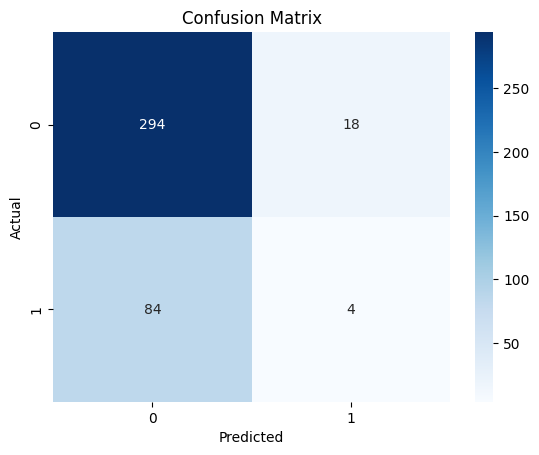

In [18]:
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
conf_matrix = confusion_matrix(y_test, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [19]:
# Step 6: Improve the Model (Example: Hyperparameter Tuning)
from sklearn.model_selection import GridSearchCV


In [20]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

In [31]:
grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [None, 5, 10],
                         'min_samples_split': [2, 5],
                         'n_estimators': [50, 100, 150]},
             scoring='accuracy')

In [32]:
print("\nAccuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.745


In [33]:
print("\nBest Parameters:", grid_search.best_params_)
best_model = grid_search.best_estimator_
joblib.dump(best_model, 'mastitis_model_optimized.pkl')
print("Optimized model saved as 'mastitis_model_optimized.pkl'")



Best Parameters: {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 50}
Optimized model saved as 'mastitis_model_optimized.pkl'


In [24]:
pip install Gradio


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.6/322.6 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 117.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 kB 7.0 MB/s eta 0:00:00


In [35]:
import gradio as gr
import joblib
import numpy as np

# Load the trained model
model = joblib.load("/content/mastitis_model_optimized.pkl")  # Or 'mastitis_model_optimized.pkl'

# Define prediction function
def predict_mastitis(temp, humidity):
    input_data = np.array([[temp, humidity]])
    prediction = model.predict(input_data)[0]
    if prediction == 1:
        return "⚠️ Mastitis Detected"
    else:
        return "✅ No Mastitis Detected"

# Create Gradio interface
interface = gr.Interface(
    fn=predict_mastitis,
    inputs=[
        gr.Slider(35.0, 42.0, step=0.1, label="Body Temperature (°C)"),
        gr.Slider(30.0, 100.0, step=1.0, label="Humidity (%)")
    ],
    outputs="text",
    title="Subclinical Mastitis Detection in Cows",
    description="Enter Body Temperature and Humidity to check for signs of subclinical mastitis."
)

# Launch the app
interface.launch()


It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://14a4871946d2109741.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


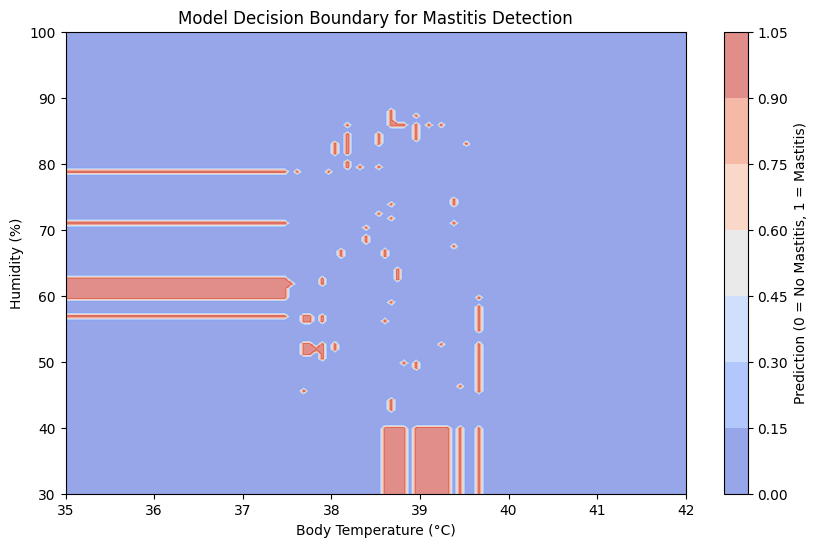

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from joblib import load

# Load model
model = load("/content/mastitis_model.pkl")

# Create a mesh grid for temperature and humidity
temp_range = np.linspace(35, 42, 100)
humidity_range = np.linspace(30, 100, 100)
xx, yy = np.meshgrid(temp_range, humidity_range)
grid = np.c_[xx.ravel(), yy.ravel()]

# Predict for each point in grid
preds = model.predict(grid).reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, preds, cmap='coolwarm', alpha=0.6)
plt.colorbar(label='Prediction (0 = No Mastitis, 1 = Mastitis)')
plt.xlabel("Body Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.title("Model Decision Boundary for Mastitis Detection")
plt.show()